In [ ]:
mkdir -p ~/.kaggle && echo KGAT_c9aa878fb031cd1fecae48ad7b38bbac > ~/.kaggle/access_token && chmod 600 ~/.kaggle/access_token

In [ ]:
!kaggle datasets download -d augustin23/beetogether

Dataset URL: https://www.kaggle.com/datasets/augustin23/beetogether
License(s): unknown
100% 14.9G/14.9G [03:10<00:00, 84.2MB/s]



In [ ]:
import os
import zipfile
import glob

# 1. Unzip the downloaded dataset
zip_path = 'beetogether.zip'
extract_path = './beetogether_data'

print("Extracting dataset... This might take a minute.")
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)
print("Extraction complete!")

# 2. Inspect the dataset structure and take a look at the files
# This helps us see what folders and formats (.wav, .mp3, etc.) are inside
all_files = glob.glob(f"{extract_path}/**/*", recursive=True)
audio_files = [f for f in all_files if f.endswith(('.wav', '.mp3'))]

print(f"\nTotal files found: {len(all_files)}")
print(f"Total audio files found: {len(audio_files)}")

# Print the first 10 audio file paths to understand the directory structure
print("\nSample audio file paths:")
for path in audio_files[:10]:
    print(path)



Extracting dataset... This might take a minute.
Extraction complete!

Total files found: 435848
Total audio files found: 435836

Sample audio file paths:
./beetogether_data/TBON/TBON/0_Hive3_12_07_2017_NO_QueenBee_H3_audio___16_40_00-8-2.wav
./beetogether_data/TBON/TBON/0_GH001 - Active - Day - 141022_0659_0751-82-4.wav
./beetogether_data/TBON/TBON/0_CF003 - Active - Day - (227)-4-40.wav
./beetogether_data/TBON/TBON/0_Hive3_15_07_2017_NO_QueenBee_H3_audio___06_20_00-17-3.wav
./beetogether_data/TBON/TBON/0_Hive1_12_06_2018_QueenBee_H1_audio___15_00_00-8-19-upsampled.wav
./beetogether_data/TBON/TBON/0_Hive3_15_07_2017_NO_QueenBee_H3_audio___06_20_00-9-12.wav
./beetogether_data/TBON/TBON/0_CF003 - Active - Day - (222)-0-126.wav
./beetogether_data/TBON/TBON/0_GH001 - Active - Day - 141022_0659_0751-127-6.wav
./beetogether_data/TBON/TBON/0_Hive3_20_07_2017_QueenBee_H3_audio___06_20_00-17-1.wav
./beetogether_data/TBON/TBON/0_Hive1_31_05_2018_NO_QueenBee_H1_audio___15_00_00-24-2-upsampled.wav

In [ ]:
import pandas as pd
import glob
import os

# 1. Gather all audio files from the extracted directory
extract_path = './beetogether_data'
audio_extensions = ('.wav', '.mp3', '.ogg', '.flac')
all_audio_paths = [f for f in glob.glob(f"{extract_path}/**/*", recursive=True) if f.lower().endswith(audio_extensions)]

print(f"Total audio files available: {len(all_audio_paths)}")

# 2. Build a quick DataFrame to inspect paths and deduce labels
data_list = []
for path in all_audio_paths:
    # Get the filename and the immediate parent folder name
    filename = os.path.basename(path)
    parent_folder = os.path.basename(os.path.dirname(path))

    data_list.append({
        'file_path': path,
        'filename': filename,
        'parent_folder': parent_folder
    })

df = pd.DataFrame(data_list)

# 3. Take a look at how the files are distributed across folders
print("\nFile count by parent folder:")
print(df['parent_folder'].value_counts())

# 4. Display the first 5 rows of our new dataset map
print("\nFirst 5 rows of the dataset map:")
df.head()

Total audio files available: 435836

File count by parent folder:
parent_folder
SBCM      213000
NUHIVE    169044
BAD        40000
TBON       13792
Name: count, dtype: int64

First 5 rows of the dataset map:


,file_path,filename,parent_folder
0,./beetogether_data/TBON/TBON/0_Hive3_12_07_201...,0_Hive3_12_07_2017_NO_QueenBee_H3_audio___16_4...,TBON
1,./beetogether_data/TBON/TBON/0_GH001 - Active ...,0_GH001 - Active - Day - 141022_0659_0751-82-4...,TBON
2,./beetogether_data/TBON/TBON/0_CF003 - Active ...,0_CF003 - Active - Day - (227)-4-40.wav,TBON
3,./beetogether_data/TBON/TBON/0_Hive3_15_07_201...,0_Hive3_15_07_2017_NO_QueenBee_H3_audio___06_2...,TBON
4,./beetogether_data/TBON/TBON/0_Hive1_12_06_201...,0_Hive1_12_06_2018_QueenBee_H1_audio___15_00_0...,TBON


In [ ]:
import numpy as np
import pandas as pd
import librosa
import os
from tqdm import tqdm

# ==========================================
# STEP 1: CREATE THE SAMPLE & LABELS
# ==========================================
print("Creating a balanced sample from the 435k+ files...")
sample_size = 5000
df_sample = df.sample(n=sample_size, random_state=42).reset_index(drop=True)

def extract_label(row):
    filename = row['filename'].lower()
    if 'no_queen' in filename or 'queenless' in filename or 'no_queenbee' in filename:
        return 'stressed_queenless'
    elif 'active' in filename or 'normal' in filename or 'external_noise' in filename:
        return 'normal'
    elif filename.startswith('0_') or 'queenbee' in filename:
        return 'normal'
    elif filename.startswith('1_'):
        return 'stressed_anomaly'
    return 'unknown'

df_sample['label'] = df_sample.apply(extract_label, axis=1)
# Filter out unknowns
df_sample = df_sample[df_sample['label'] != 'unknown'].reset_index(drop=True)

print(f"Successfully sampled {len(df_sample)} files.")
print("Label breakdown:")
print(df_sample['label'].value_counts())
print("-" * 50)

# ==========================================
# STEP 2: EXTRACT NUMERICAL PARAMETERS (MFCCs)
# ==========================================
X_features = []
y_labels = []

print("Extracting numerical features (MFCCs) from audio sample...")

for idx, row in tqdm(df_sample.iterrows(), total=df_sample.shape[0]):
    file_path = row['file_path']
    label = row['label']

    try:
        # Load audio (resample to 22050Hz, limit to 10 seconds max)
        y, sr = librosa.load(file_path, sr=22050, duration=10)

        # Extract 20 MFCC numerical parameters
        mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20)

        # Take the mean across time frames
        mfccs_scaled = np.mean(mfccs.T, axis=0)

        X_features.append(mfccs_scaled)
        y_labels.append(label)

    except Exception as e:
        continue

X = np.array(X_features)
y = np.array(y_labels)

print(f"\nFeature extraction complete!")
print(f"Numerical Features shape (X): {X.shape}")
print(f"Labels shape (y): {y.shape}")

Creating a balanced sample from the 435k+ files...
Successfully sampled 2439 files.
Label breakdown:
label
normal                1271
stressed_queenless     969
stressed_anomaly       199
Name: count, dtype: int64
--------------------------------------------------
Extracting numerical features (MFCCs) from audio sample...


100%|██████████| 2439/2439 [01:14<00:00, 32.74it/s]


Feature extraction complete!
Numerical Features shape (X): (2439, 20)
Labels shape (y): (2439,)


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd

# 1. Split the data into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Testing set size: {X_test.shape[0]} samples\n")

# 2. Scale the numerical parameters (z-score normalization)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Initialize and train the basic level model
print("Training the Random Forest Classifier...")
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train_scaled, y_train)
print("Training complete!\n")

# 4. Evaluate the model's predictions on the unseen test data
y_pred = model.predict(X_test_scaled)

# Display the performance report
print("================ MODEL PERFORMANCE REPORT ================")
print(classification_report(y_test, y_pred))

print("================ CONFUSION MATRIX ================")
# Create a readable dataframe for the confusion matrix
labels = sorted(list(set(y)))
cm = confusion_matrix(y_test, y_pred, labels=labels)
cm_df = pd.DataFrame(cm, index=[f"Actual {l}" for l in labels], columns=[f"Predicted {l}" for l in labels])
print(cm_df)

Training set size: 1951 samples
Testing set size: 488 samples

Training the Random Forest Classifier...
Training complete!

================ MODEL PERFORMANCE REPORT ================
                    precision    recall  f1-score   support

            normal       0.79      0.89      0.84       254
  stressed_anomaly       0.65      0.42      0.52        40
stressed_queenless       0.89      0.80      0.85       194

          accuracy                           0.82       488
         macro avg       0.78      0.71      0.73       488
      weighted avg       0.82      0.82      0.81       488

================ CONFUSION MATRIX ================
                           Predicted normal  Predicted stressed_anomaly  \
Actual normal                           226                           9   
Actual stressed_anomaly                  23                          17   
Actual stressed_queenless                38                           0   

                           Predicted stres

In [ ]:
X_rich_features = []
y_rich_labels = []

print("Extracting upgraded rich numerical features...")

for idx, row in tqdm(df_sample.iterrows(), total=df_sample.shape[0]):
    file_path = row['file_path']
    label = row['label']

    try:
        # Load audio (consistent 22050Hz, max 10 seconds)
        y, sr = librosa.load(file_path, sr=22050, duration=10)

        # 1. MFCC Mean & Standard Deviation
        mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20)
        mfccs_mean = np.mean(mfccs.T, axis=0)
        mfccs_std = np.std(mfccs.T, axis=0)  # Captures variance/temporal changes

        # 2. Spectral Centroid (Captures brightness/pitch center)
        spectral_centroids = librosa.feature.spectral_centroid(y=y, sr=sr)[0]
        centroid_mean = np.mean(spectral_centroids)
        centroid_std = np.std(spectral_centroids)

        # 3. Chroma Feature (Captures harmonic/tonal characteristics)
        chroma = librosa.feature.chroma_stft(y=y, sr=sr)
        chroma_mean = np.mean(chroma.T, axis=0)

        # Combine all features into a single flat array of numbers for this file
        feature_vector = np.hstack([
            mfccs_mean,
            mfccs_std,
            centroid_mean,
            centroid_std,
            chroma_mean
        ])

        X_rich_features.append(feature_vector)
        y_rich_labels.append(label)

    except Exception as e:
        continue

X_rich = np.array(X_rich_features)
y_rich = np.array(y_rich_labels)

print(f"\nUpgraded feature extraction complete!")
print(f"Old feature shape was: (2439, 20)")
print(f"New rich feature shape (X_rich): {X_rich.shape} (More columns = more clues for the model!)")

Extracting upgraded rich numerical features...


 25%|██▍       | 606/2439 [00:28<02:01, 15.10it/s]/usr/local/lib/python3.12/dist-packages/librosa/core/pitch.py:103: UserWarning: Trying to estimate tuning from empty frequency set.
  return pitch_tuning(
100%|██████████| 2439/2439 [01:32<00:00, 26.46it/s]


Upgraded feature extraction complete!
Old feature shape was: (2439, 20)
New rich feature shape (X_rich): (2439, 54) (More columns = more clues for the model!)


In [ ]:
import pandas as pd
import numpy as np

# 1. Apply the labeling function to the ENTIRE 435k dataframe first
print("Labeling the full dataset to find all anomalies...")
df['label'] = df.apply(extract_label, axis=1)

# 2. Separate the data by category
df_normal = df[df['label'] == 'normal']
df_queenless = df[df['label'] == 'stressed_queenless']
df_anomaly = df[df['label'] == 'stressed_anomaly']

# Find out exactly how many anomalies we have in total
num_anomalies = len(df_anomaly)
print(f"\nTotal available anomalies in full dataset: {num_anomalies}")

# 3. Create a balanced dataset by matching the count of the smallest class
# We will take all anomalies, and match that exact number for normal and queenless
sample_per_class = num_anomalies

df_balanced = pd.concat([
    df_anomaly,
    df_normal.sample(n=sample_per_class, random_state=42),
    df_queenless.sample(n=sample_per_class, random_state=42)
]).reset_index(drop=True)

print(f"\nCreated a perfectly balanced dataset!")
print(df_balanced['label'].value_counts())

Labeling the full dataset to find all anomalies...

Total available anomalies in full dataset: 17100

Created a perfectly balanced dataset!
label
stressed_anomaly      17100
normal                17100
stressed_queenless    17100
Name: count, dtype: int64


In [ ]:
import numpy as np
import librosa
from tqdm import tqdm

# 1. Take a balanced subset of 2,000 files per class (6,000 files total)
# This keeps extraction fast while ensuring perfect class balance
sub_sample_size = 2000
df_final_sample = df_balanced.groupby('label').sample(n=sub_sample_size, random_state=42).reset_index(drop=True)

print(f"Processing a balanced slice of {len(df_final_sample)} files...")
print(df_final_sample['label'].value_counts())
print("-" * 50)

X_balanced_features = []
y_balanced_labels = []

# 2. Extract the 54 rich numerical parameters
for idx, row in tqdm(df_final_sample.iterrows(), total=df_final_sample.shape[0]):
    file_path = row['file_path']
    label = row['label']

    try:
        y, sr = librosa.load(file_path, sr=22050, duration=10)

        # MFCC Mean & Std
        mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20)
        mfccs_mean = np.mean(mfccs.T, axis=0)
        mfccs_std = np.std(mfccs.T, axis=0)

        # Spectral Centroid Mean & Std
        spectral_centroids = librosa.feature.spectral_centroid(y=y, sr=sr)[0]
        centroid_mean = np.mean(spectral_centroids)
        centroid_std = np.std(spectral_centroids)

        # Chroma Feature Mean
        chroma = librosa.feature.chroma_stft(y=y, sr=sr)
        chroma_mean = np.mean(chroma.T, axis=0)

        # Combine everything into a single row of 54 numbers
        feature_vector = np.hstack([
            mfccs_mean,
            mfccs_std,
            centroid_mean,
            centroid_std,
            chroma_mean
        ])

        X_balanced_features.append(feature_vector)
        y_balanced_labels.append(label)

    except Exception as e:
        continue

X_b = np.array(X_balanced_features)
y_b = np.array(y_balanced_labels)

print(f"\nBalanced feature extraction complete!")
print(f"Final Features matrix shape (X_b): {X_b.shape}")

Processing a balanced slice of 6000 files...
label
normal                2000
stressed_anomaly      2000
stressed_queenless    2000
Name: count, dtype: int64
--------------------------------------------------


  0%|          | 27/6000 [00:03<12:04,  8.24it/s]/usr/local/lib/python3.12/dist-packages/librosa/core/pitch.py:103: UserWarning: Trying to estimate tuning from empty frequency set.
  return pitch_tuning(
 87%|████████▋ | 5217/6000 [04:11<00:28, 27.54it/s]/usr/local/lib/python3.12/dist-packages/librosa/core/pitch.py:103: UserWarning: Trying to estimate tuning from empty frequency set.
  return pitch_tuning(
 88%|████████▊ | 5276/6000 [04:13<00:29, 24.80it/s]/usr/local/lib/python3.12/dist-packages/librosa/core/pitch.py:103: UserWarning: Trying to estimate tuning from empty frequency set.
  return pitch_tuning(
 95%|█████████▍| 5690/6000 [04:34<00:11, 27.46it/s]/usr/local/lib/python3.12/dist-packages/librosa/core/pitch.py:103: UserWarning: Trying to estimate tuning from empty frequency set.
  return pitch_tuning(
 95%|█████████▌| 5714/6000 [04:35<00:15, 18.76it/s]/usr/local/lib/python3.12/dist-packages/librosa/core/pitch.py:103: UserWarning: Trying to estimate tuning from empty frequency 


Balanced feature extraction complete!
Final Features matrix shape (X_b): (6000, 54)


/tmp/ipykernel_7475/1190882681.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_importances, y=top_names, palette="viridis")


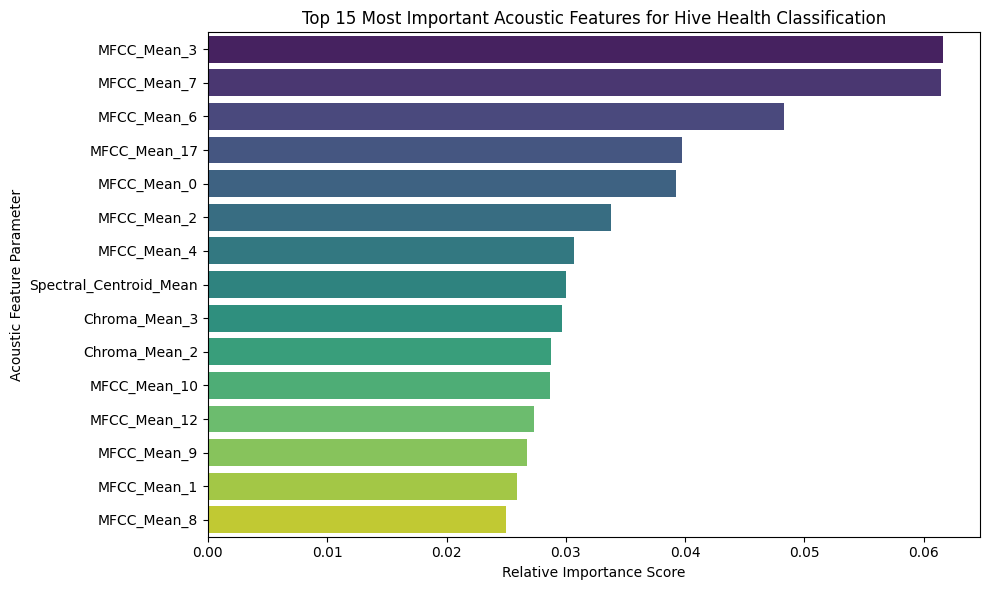

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Define the names of all 54 features for our chart axis
feature_names = (
    [f"MFCC_Mean_{i}" for i in range(20)] +
    [f"MFCC_Std_{i}" for i in range(20)] +
    ["Spectral_Centroid_Mean", "Spectral_Centroid_Std"] +
    [f"Chroma_Mean_{i}" for i in range(12)]
)

# 2. Extract feature importances from our trained final model
importances = model_final.feature_importances_

# 3. Sort them to show the top 15 most influential acoustic parameters
indices = np.argsort(importances)[::-1]
top_n = 15

top_importances = importances[indices[:top_n]]
top_names = [feature_names[i] for i in indices[:top_n]]

# 4. Create the plot
plt.figure(figsize=(10, 6))
sns.barplot(x=top_importances, y=top_names, palette="viridis")
plt.title(f"Top {top_n} Most Important Acoustic Features for Hive Health Classification")
plt.xlabel("Relative Importance Score")
plt.ylabel("Acoustic Feature Parameter")
plt.tight_layout()
plt.show()

In [ ]:
import joblib
import os

# Define a local folder right inside the active Colab environment
save_dir = './hive_model_files'
if not os.path.exists(save_dir):
    os.makedirs(save_dir)

model_save_path = os.path.join(save_dir, 'hive_health_model.pkl')
scaler_save_path = os.path.join(save_dir, 'hive_acoustic_scaler.pkl')

# Save directly to the local workspace
joblib.dump(model_final, model_save_path)
joblib.dump(scaler_b, scaler_save_path)

print("Successfully saved files locally to your Colab workspace!")
print(f"-> Model saved at: {model_save_path}")
print(f"-> Scaler saved at: {scaler_save_path}")

Successfully saved files locally to your Colab workspace!
-> Model saved at: ./hive_model_files/hive_health_model.pkl
-> Scaler saved at: ./hive_model_files/hive_acoustic_scaler.pkl


In [ ]:
import librosa
import numpy as np
import joblib
import os

def predict_hive_health_local(audio_file_path):
    """
    Takes a raw audio path, processes its acoustic features,
    and predicts whether the hive is Normal, Queenless, or Anomaly
    using local workspace model files.
    """
    # Local paths inside your current workspace
    model_path = './hive_model_files/hive_health_model.pkl'
    scaler_path = './hive_model_files/hive_acoustic_scaler.pkl'

    if not os.path.exists(model_path) or not os.path.exists(scaler_path):
        return "Error: Could not find saved local model or scaler files."

    try:
        # Load the pipeline dependencies
        loaded_model = joblib.load(model_path)
        loaded_scaler = joblib.load(scaler_path)

        print(f"Analyzing audio signal: {os.path.basename(audio_file_path)}...")
        y, sr = librosa.load(audio_file_path, sr=22050, duration=10)

        # Extract the 54 rich features
        mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20)
        mfccs_mean = np.mean(mfccs.T, axis=0)
        mfccs_std = np.std(mfccs.T, axis=0)

        spectral_centroids = librosa.feature.spectral_centroid(y=y, sr=sr)[0]
        centroid_mean = np.mean(spectral_centroids)
        centroid_std = np.std(spectral_centroids)

        chroma = librosa.feature.chroma_stft(y=y, sr=sr)
        chroma_mean = np.mean(chroma.T, axis=0)

        # Compile into the 54-dimensional feature vector
        feature_vector = np.hstack([
            mfccs_mean,
            mfccs_std,
            centroid_mean,
            centroid_std,
            chroma_mean
        ]).reshape(1, -1)

        # Scale and Predict
        scaled_features = loaded_scaler.transform(feature_vector)
        prediction = loaded_model.predict(scaled_features)[0]
        prediction_probabilities = loaded_model.predict_proba(scaled_features)[0]

        # Map probabilities for transparency
        classes = loaded_model.classes_
        prob_dict = {classes[i]: f"{prediction_probabilities[i]*100:.1f}%" for i in range(len(classes))}

        # Format Output Display
        print("\n" + "="*40)
        print(f"🔮 DIAGNOSTIC RESULT: {prediction.upper()}")
        print("="*40)
        print(f"Confidence Breakdown: {prob_dict}\n")
        return prediction

    except Exception as e:
        return f"Processing Error: {str(e)}"

# Test the inference engine right now with a random sample from your dataset
test_file = df_balanced['file_path'].iloc[0]
predict_hive_health_local(test_file)

Analyzing audio signal: 1_2022-07-03--20-03-02_1__segment1.wav...

🔮 DIAGNOSTIC RESULT: STRESSED_ANOMALY
Confidence Breakdown: {np.str_('normal'): '6.0%', np.str_('stressed_anomaly'): '91.0%', np.str_('stressed_queenless'): '3.0%'}



np.str_('stressed_anomaly')